In [2]:
import pandas as pd

In [3]:
df = pd.read_csv("../data/ai-impact-jobs-layoff-risk-dataset.csv")
df.head()

,Age,Education_Level,Years_of_Experience,Industry,Job_Role,Company_Size,Job_Level,Routine_Task_Percentage,Creativity_Requirement,Human_Interaction_Level,AI_Adoption_Level,Number_of_AI_Tools_Used,AI_Usage_Hours_Per_Week,Tasks_Automated_Percentage,AI_Training_Hours,Layoff_Risk
0,59,Master's,6,Finance,Accountant,Medium,Entry,84,21,94,Medium,5,7,40,26,High
1,44,Master's,14,Manufacturing,Production Supervisor,Small,Entry,30,84,68,Low,2,2,14,9,Low
2,36,Bachelor's,7,Retail,Store Manager,Medium,Senior,12,86,71,Low,0,1,6,3,Low
3,27,Bachelor's,6,Finance,Auditor,Large,Entry,90,18,21,Medium,3,10,67,26,High
4,49,High School,12,Finance,Auditor,Small,Entry,49,52,72,Medium,5,13,26,19,Medium


              precision    recall  f1-score   support

        High       0.91      0.93      0.92      1360
         Low       0.92      0.90      0.91      1320
      Medium       0.83      0.83      0.83      1320

    accuracy                           0.89      4000
   macro avg       0.89      0.89      0.89      4000
weighted avg       0.89      0.89      0.89      4000


Top 15 Important Features:
Routine_Task_Percentage        0.166225
Creativity_Requirement         0.139559
Tasks_Automated_Percentage     0.139395
Job_Level                      0.080287
Human_Interaction_Level        0.057468
AI_Training_Hours              0.047203
AI_Usage_Hours_Per_Week        0.046722
Years_of_Experience            0.041739
AI_Adoption_Level              0.038548
Age                            0.035012
Number_of_AI_Tools_Used        0.033862
Education_Level_High School    0.015588
Education_Level_Master's       0.014101
Industry_Manufacturing         0.011997
Industry_Healthcare            

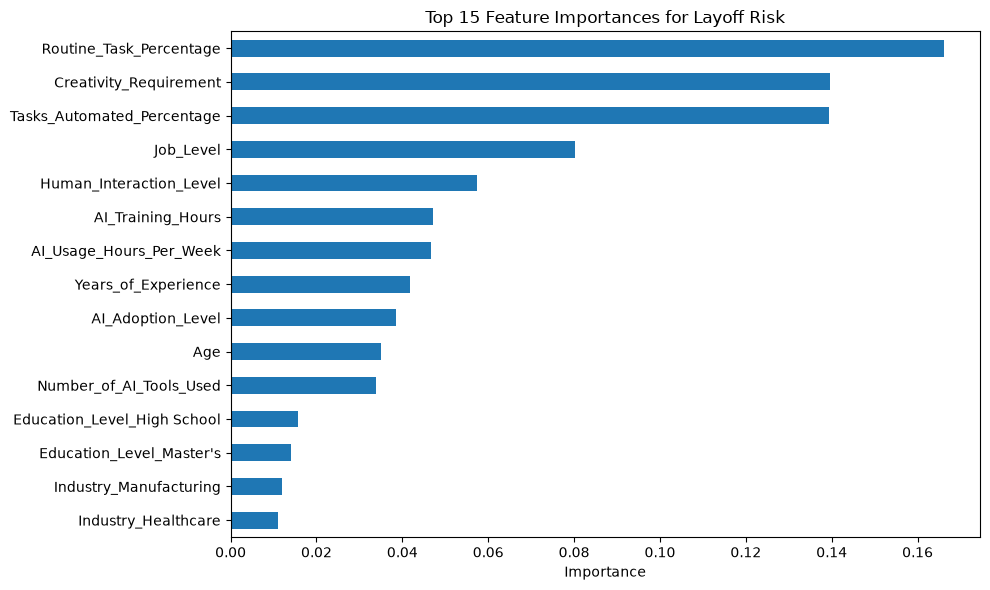

In [4]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
import pandas as pd
import matplotlib.pyplot as plt

# One-hot encoding for nominal categorical columns
X_fi = pd.get_dummies(
    df.drop(columns=["Layoff_Risk"]),
    columns=["Education_Level", "Industry", "Job_Role", "Company_Size"],
    drop_first=True
)

# Ordinal encoding for ordered categories
job_level_map = {"Entry": 0, "Mid": 1, "Senior": 2}
ai_adoption_map = {"Low": 0, "Medium": 1, "High": 2}

X_fi["Job_Level"] = X_fi["Job_Level"].map(job_level_map)
X_fi["AI_Adoption_Level"] = X_fi["AI_Adoption_Level"].map(ai_adoption_map)

y_fi = df["Layoff_Risk"]

X_train, X_test, y_train, y_test = train_test_split(
    X_fi, y_fi,
    test_size=0.2,
    random_state=42,
    stratify=y_fi
)

rf = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

print(classification_report(y_test, rf.predict(X_test)))

importance = pd.Series(rf.feature_importances_, index=X_fi.columns)
importance = importance.sort_values(ascending=False)

print("\nTop 15 Important Features:")
print(importance.head(15))

plt.figure(figsize=(10, 6))
importance.head(15).sort_values().plot(kind="barh")
plt.title("Top 15 Feature Importances for Layoff Risk")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

In [6]:
job_level_map = {"Entry": 0, "Mid": 1, "Senior": 2}
ai_adoption_map = {"Low": 0, "Medium": 1, "High": 2}
layoff_risk_map = {"Low": 0, "Medium": 1, "High": 2}

df["Job_Level_Encoded"] = df["Job_Level"].map(job_level_map)
df["AI_Adoption_Level_Encoded"] = df["AI_Adoption_Level"].map(ai_adoption_map)
df["Layoff_Risk_Encoded"] = df["Layoff_Risk"].map(layoff_risk_map)

df[["Job_Level", "Job_Level_Encoded",
    "AI_Adoption_Level", "AI_Adoption_Level_Encoded",
    "Layoff_Risk", "Layoff_Risk_Encoded"]].head()

,Job_Level,Job_Level_Encoded,AI_Adoption_Level,AI_Adoption_Level_Encoded,Layoff_Risk,Layoff_Risk_Encoded
0,Entry,0,Medium,1,High,2
1,Entry,0,Low,0,Low,0
2,Senior,2,Low,0,Low,0
3,Entry,0,Medium,1,High,2
4,Entry,0,Medium,1,Medium,1


In [7]:
selected_features = [
    "Routine_Task_Percentage",
    "Creativity_Requirement",
    "Tasks_Automated_Percentage",
    "Job_Level_Encoded",
    "Human_Interaction_Level",
    "AI_Training_Hours",
    "AI_Usage_Hours_Per_Week",
    "Years_of_Experience",
    "AI_Adoption_Level_Encoded",
    "Number_of_AI_Tools_Used"
]

df[selected_features].to_csv("selected_features_for_clustering.csv", index=False)

In [8]:
print("Job_Level_Encoded" in df.columns)
print("AI_Adoption_Level_Encoded" in df.columns)

True
True


In [9]:
selected_features = [
    "Routine_Task_Percentage",
    "Creativity_Requirement",
    "Tasks_Automated_Percentage",
    "Job_Level_Encoded",
    "Human_Interaction_Level",
    "AI_Training_Hours",
    "AI_Usage_Hours_Per_Week",
    "Years_of_Experience",
    "AI_Adoption_Level_Encoded",
    "Number_of_AI_Tools_Used"
]

final_data = df[selected_features].copy()
final_data["Layoff_Risk"] = df["Layoff_Risk"]

final_data.to_csv("final_clustering_data.csv", index=False)